# Shared recommendation baselines

These baselines rank the same eligible users for each track in the fixed validation split. User activity and tag profiles use only training plays before 2018-01-01.

- **Random** draws 1,000 distinct users uniformly without replacement for each track, using seed 42 and sorted track order. It measures how much recall the size of the recommendation list alone provides.
- **Most-active** ranks users by $a_u=\sum_j R_{uj}$, the total number of training plays, and uses that order for every track. It measures the value of historical activity alone.
- **Tag profile** computes $P=RX_{\mathrm{train}}$, where $R$ contains raw play counts and $X_{\mathrm{train}}$ contains TF-IDF features. It ranks users by cosine similarity $\widetilde{P}\widetilde{X}_{\mathrm{eval}}^\top$, where the tilde denotes row-wise L2 normalization.

Activity and similarity ties use ascending user ID. A zero profile or track feature vector has zero similarity. User batches bound the profile and score allocations. After scoring a batch, each track keeps its best 1,000 users seen so far.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "pyproject.toml").is_file():
    root = root.parent
sys.path.insert(0, str(root))

from scripts.models.baselines import generate_baselines

predictions, activity, diagnostics = generate_baselines("validation", root)

## Activity and computational cost

Recommendation timings exclude input loading, Parquet export, and evaluation. Tag-profile recommendation time includes the profile construction and normalization reported below.

Median activity was **668 plays**, and the 95th percentile was **7,933**.

Profiles have shape **105,578 × 166,737** with **687,577,502** nonzeros (3.91% density). One combined CSR would occupy **5,246.2 MiB**. The largest profile batch occupied **159.5 MiB**, and the largest dense score block occupied **10.0 MiB**. There were **0** zero profiles and **9** zero-feature validation tracks.

| Operation | Seconds |
| --- | ---: |
| Random recommendations | 0.01 |
| Most Active recommendations | 0.02 |
| Tag Profile recommendations | 35.06 |
| Profile construction and normalization | 24.83 |

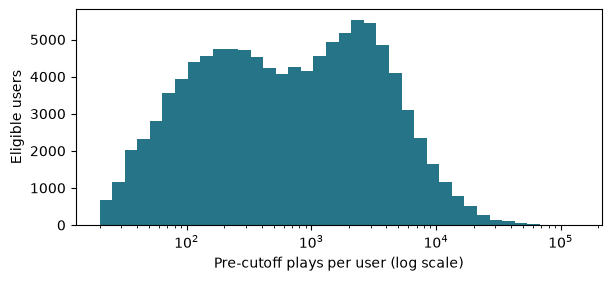

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

profile = diagnostics["profile"]
rows, columns = profile["shape"]
nonzeros = profile["nnz"]
index_bytes = 4 if max(rows, columns, nonzeros) <= np.iinfo(np.int32).max else 8
csr_bytes = nonzeros * (4 + index_bytes) + (rows + 1) * index_bytes
mib = 2**20
median, p95 = np.percentile(activity, [50, 95])
display(Markdown(
    f"Median activity was **{median:,.0f} plays**, and the 95th percentile was **{p95:,.0f}**.\n\n"
    f"Profiles have shape **{rows:,} × {columns:,}** with **{nonzeros:,}** nonzeros "
    f"({nonzeros / (rows * columns):.2%} density). One combined CSR would occupy "
    f"**{csr_bytes / mib:,.1f} MiB**. The largest profile batch occupied "
    f"**{profile['peak_profile_batch_bytes'] / mib:.1f} MiB**, and the largest dense score block "
    f"occupied **{profile['peak_score_block_bytes'] / mib:.1f} MiB**. "
    f"There were **{profile['zero_profiles']:,}** zero profiles and "
    f"**{profile['zero_feature_tracks']:,}** zero-feature validation tracks."
))

times = ["| Operation | Seconds |", "| --- | ---: |"]
for name, seconds in diagnostics["seconds"].items():
    times.append(f"| {name.replace('_', ' ').title()} recommendations | {seconds:.2f} |")
times.append(f"| Profile construction and normalization | {profile['profile_seconds']:.2f} |")
display(Markdown("\n".join(times)))

fig, ax = plt.subplots(figsize=(6, 2.7), layout="constrained")
ax.hist(activity, bins=np.geomspace(activity.min(), activity.max(), 39), color="#267487")
ax.set(xscale="log", xlabel="Pre-cutoff plays per user (log scale)", ylabel="Eligible users")
plt.show()
plt.close(fig)

## Validation comparison

Under uniform sampling, each relevant user has probability $K/m$ of appearing in the first $K$ ranks, where $m$ is the eligible-user count. Therefore the expected Random Recall@$K$ is $K/m$ for every track with observed listeners. The table reports macro averages from the shared evaluator.

In [3]:
from scripts.common.evaluate import RANK_CUTOFFS, evaluate

cutoffs = RANK_CUTOFFS
header = ["Model", *(f"Recall@{k}" for k in cutoffs), *(f"NDCG@{k}" for k in cutoffs)]
table = ["| " + " | ".join(header) + " |", "| --- |" + " ---: |" * (2 * len(cutoffs))]
for name, path in predictions.items():
    tracks, zero_listeners, metrics = evaluate(path, "validation", root / "data/splits")
    _, recall, ndcg = zip(*metrics)
    values = " | ".join(f"{value:.6f}" for value in (*recall, *ndcg))
    table.append(f"| {name.replace('_', ' ').title()} | {values} |")
expected = " | ".join(f"{k / len(activity):.6f}" for k in cutoffs)
table.append(f"| Random expectation | {expected} | — | — | — |")
display(Markdown(
    f"**{tracks - zero_listeners:,}** of {tracks:,} validation tracks contributed to the averages. "
    f"The eligible pool contained {len(activity):,} users.\n\n" + "\n".join(table)
))

**1,274** of 1,274 validation tracks contributed to the averages. The eligible pool contained 105,578 users.

| Model | Recall@100 | Recall@500 | Recall@1000 | NDCG@100 | NDCG@500 | NDCG@1000 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Random | 0.000779 | 0.005046 | 0.010405 | 0.000944 | 0.002684 | 0.004629 |
| Most Active | 0.009648 | 0.074019 | 0.134166 | 0.011070 | 0.036974 | 0.059712 |
| Tag Profile | 0.027603 | 0.107185 | 0.158301 | 0.028928 | 0.055730 | 0.075781 |
| Random expectation | 0.000947 | 0.004736 | 0.009472 | — | — | — |

## Test Evaluation

Apply the existing Random, Most Active, and Tag Profile configurations to the held-out test tracks. Activity and tag profiles use training interactions only.

In [4]:
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = Path.cwd()
if not (root / "pyproject.toml").is_file():
    root = root.parent
sys.path.insert(0, str(root))

from scripts.common.evaluate import RANK_CUTOFFS, evaluate
from scripts.models.baselines import generate_baselines

paths, _, _ = generate_baselines("test", root)
test_predictions = {name.replace("_", " ").title(): path for name, path in paths.items()}

header = ["Model", *(f"Recall@{k}" for k in RANK_CUTOFFS), *(f"NDCG@{k}" for k in RANK_CUTOFFS)]
rows = ["| " + " | ".join(header) + " |", "| --- |" + " ---: |" * (2 * len(RANK_CUTOFFS))]
for label, path in test_predictions.items():
    total, zero, metrics = evaluate(path, "test", root / "data/splits")
    _, recall, ndcg = zip(*metrics)
    rows.append(f"| {label} | " + " | ".join(f"{value:.6f}" for value in (*recall, *ndcg)) + " |")
display(Markdown(f"**{total - zero:,}** of {total:,} test tracks contributed.\n\n" + "\n".join(rows)))

**1,299** of 1,299 test tracks contributed.

| Model | Recall@100 | Recall@500 | Recall@1000 | NDCG@100 | NDCG@500 | NDCG@1000 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Random | 0.000678 | 0.004497 | 0.009080 | 0.000818 | 0.002404 | 0.004306 |
| Most Active | 0.012020 | 0.069816 | 0.124902 | 0.010990 | 0.035233 | 0.055696 |
| Tag Profile | 0.028827 | 0.098073 | 0.154911 | 0.028780 | 0.053430 | 0.075075 |